# **Testing Notebook for Results**
---

## Import Packages

In [29]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from evtpooling import (
    alpha_var_agg_plot,
    alpha_var_sing_plot,
    autocorrelation_test,
    basel_backtesting,
    chenzhou,
    dm_test,
    etl_pipeline,
    get_alpha_dict,
    get_var_dict,
    kmeans_plot,
    kmeans_pooling,
    loss_return_plot,
    normality_test,
    rmtc_pooling,
    sener_backtesting,
    stationarity_test,
    wald_test,
)

## <-- <i>Click here to collapse ETL Pipeline</i>

<hr>
<br>
<center>
<h2><b><span style="color:yellow">ETL Pipeline</span></b></h2>
</center>
<hr>

### `Original data`

In [30]:
# ====== File paths ======
file_path = r"C:\Users\jkim595\OneDrive - KPMG\Documents\Thesis\figures"


# ====== ETL pipeline ======
print("=" * 30 + "ETL Pipeline" + "=" * 30 + "\n")
losses_week, losses_day = etl_pipeline(
    r"C:\Users\jkim595\OneDrive - KPMG\Documents\Thesis\venv\data\STOXX_complete_data.csv",
    return_day_data=True,
    save_file=True,
)
print("\n" + "=" * 72 + "\n")

==============================ETL Pipeline==============================

Detected encoding: ascii with confidence 1.0
Auto-detected separator: ','
File loaded successfully: C:\Users\jkim595\OneDrive - KPMG\Documents\Thesis\venv\data\STOXX_complete_data.csv with shape (1208483, 16)
✅ Data validation passed.
✅ Stocks with valid date coverage found: 134
✅ Stocks with valid price completeness found: 97
✅ Best groups selected based on curcdd preference and completeness: 66
✅ Excel file written: C:\Users\jkim595\OneDrive - KPMG\Documents\Thesis\venv\data\losses_week.xlsx
✅ Excel file written: C:\Users\jkim595\OneDrive - KPMG\Documents\Thesis\venv\data\losses_day.xlsx




#### `dictionary gvkey:conm`
This is a mapping from the unique identifier (*gvkey*) to the shortened name of the company for the original data

In [31]:
dict_gvkey_conm = {
    12673: "BARCLAYS", 24578: "SWEDBANK", 14140: "SANTANDER", 24584: "MPS", 15181: "BBVA",
    24826: "TOPDANMARK", 15509: "HSBC", 28838: "CREDIT SUISSE", 15522: "BPE", 62410: "ALPHA & HOLDINGS",
    15532: "BNP PARIBAS", 63120: "AXA", 15545: "AVIVA", 63546: "SWISS RE", 15547: "NATIXIS",
    63590: "BANK OF IRELAND", 15549: "UNICREDIT", 63759: "SCOR", 15552: "DANSKE", 144496: "UBS GROUP AG",
    15575: "COMMERZBANK", 200646: "SONDRIO BANK", 15576: "DEUTSCHE", 200647: "BPER BANCA", 15593: "MEDIOBANCA",
    200705: "DNB BANK ASA", 15598: "AEGON", 204719: "KOMERCNI BANKA", 15600: "JYSKE", 204825: "HANNOVER RUECK",
    15603: "LEGAL & GEN", 205699: "SWISS LIFE", 15617: "ING", 209212: "SYDBANK", 15634: "NATWEST",
    214659: "ERSTE BK", 15645: "STD CHARTERED", 214881: "NORDEA BANK ABP", 15654: "HANDELSBANKEN", 220426: "ZURICH",
    15664: "RSA", 223504: "ABRDN", 15671: "SEB", 225081: "BANCO BPM", 15703: "KBC",
    225244: "CNP", 15724: "ALLIANZ", 227537: "EUROBANK", 15773: "SAMPO", 227616: "HISCOX",
    15782: "PRUDENTIAL", 229039: "OLD MUTUAL", 15784: "SG", 241498: "MPC", 15804: "A. GENERALI",
    245436: "SABADELL", 15846: "BANKINTER", 254578: "BEAZLEY", 15914: "UNIPOLSAI", 260840: "NN GROUP N.V.",
    15929: "LLOYDS", 268159: "DIRECT LINE", 16281: "MAPFRE", 270266: "UBI BANCA", 16348: "INTESA SANPAOLO",
    270979: "ADMIRAL", 16349: "HELVETIA", 272817: "RAIFFEISEN", 16447: "AGEAS SA/NV", 274282: "TRYG",
    23087: "BALOISE", 274774: "LANCASHIRE", 23848: "BCP", 286879: "CAIXABANK", 23913: "ST JAMES PLACE",
    288153: "PHOENIX", 24563: "CREDIT AGRICOLE", 292854: "JULIUS BAER", 296091: "GJENSIDIGE",
}

## <-- <i>Click here to collapse Data Characteristics</i>

<hr>
<br>
<center>
<h2><b><span style="color:blue">Data Characteristics</span></b></h2>
</center>
<hr>

### `IID assumption testing`

In [32]:
# ====== IID assumption testing ======
print("=" * 30 + "IID Assumption Testing" + "=" * 30 + "\n")
normality_test(losses_week, drop=True, dict_gvkey_conm=dict_gvkey_conm)
autocorrelation_test(losses_week, drop=True, dict_gvkey_conm=dict_gvkey_conm)
stationarity_test(losses_week, drop=True, dict_gvkey_conm=dict_gvkey_conm)

normality_test(losses_day, drop=True, dict_gvkey_conm=dict_gvkey_conm)
autocorrelation_test(losses_day, drop=True, dict_gvkey_conm=dict_gvkey_conm)
stationarity_test(losses_day, drop=True, dict_gvkey_conm=dict_gvkey_conm)

losses_week_est = losses_week[losses_week.index <= "2018-12-31"]
losses_day_est = losses_day[losses_day.index <= "2018-12-31"]

losses_week_eval = losses_week[losses_week.index > "2018-12-31"]
losses_day_eval = losses_day[losses_day.index > "2018-12-31"]
print("\n" + "=" * 82 + "\n")

==============================IID Assumption Testing==============================

The following companies failed to reject the null hypothesis of normality (p-value > 0.05): []
The following companies rejected the null hypothesis of no autocorrelation (p-value < 0.05): ['AEGON', 'SEB', 'LLOYDS', 'SWEDBANK', 'BPER BANCA', 'NORDEA BANK ABP', 'HISCOX', 'SABADELL']
The following companies failed to reject the null hypothesis of a unit root (p-value < 0.05): []
The following companies failed to reject the null hypothesis of normality (p-value > 0.05): []
The following companies rejected the null hypothesis of no autocorrelation (p-value < 0.05): ['BARCLAYS', 'BNP PARIBAS', 'AVIVA', 'DEUTSCHE', 'AEGON', 'LEGAL & GEN', 'ING', 'HANDELSBANKEN', 'ALLIANZ', 'SAMPO', 'PRUDENTIAL', 'LLOYDS', 'INTESA SANPAOLO', 'ST JAMES PLACE', 'SWEDBANK', 'AXA', 'SWISS RE', 'HANNOVER RUECK', 'SWISS LIFE', 'SYDBANK', 'ZURICH', 'SABADELL', 'LANCASHIRE']
The following companies failed to reject the null hypothesis 

#### `Losses dictionaries`

In [33]:
# ====== Losses dictionaries ======
losses_week_dict = {col: losses_week_est[col].dropna() for col in losses_week_est.columns}
losses_day_dict = {col: losses_day_est[col].dropna() for col in losses_day_est.columns}

### `Alpha & VaR plots`

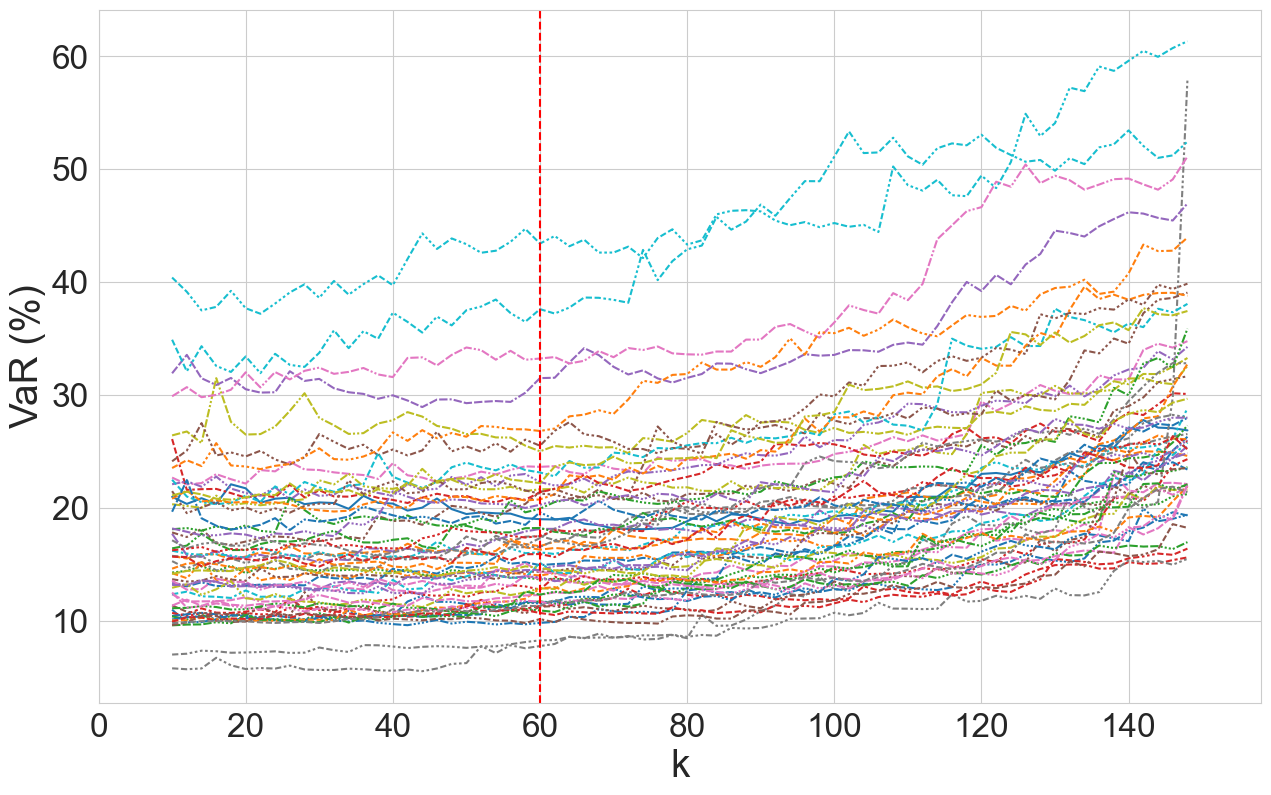

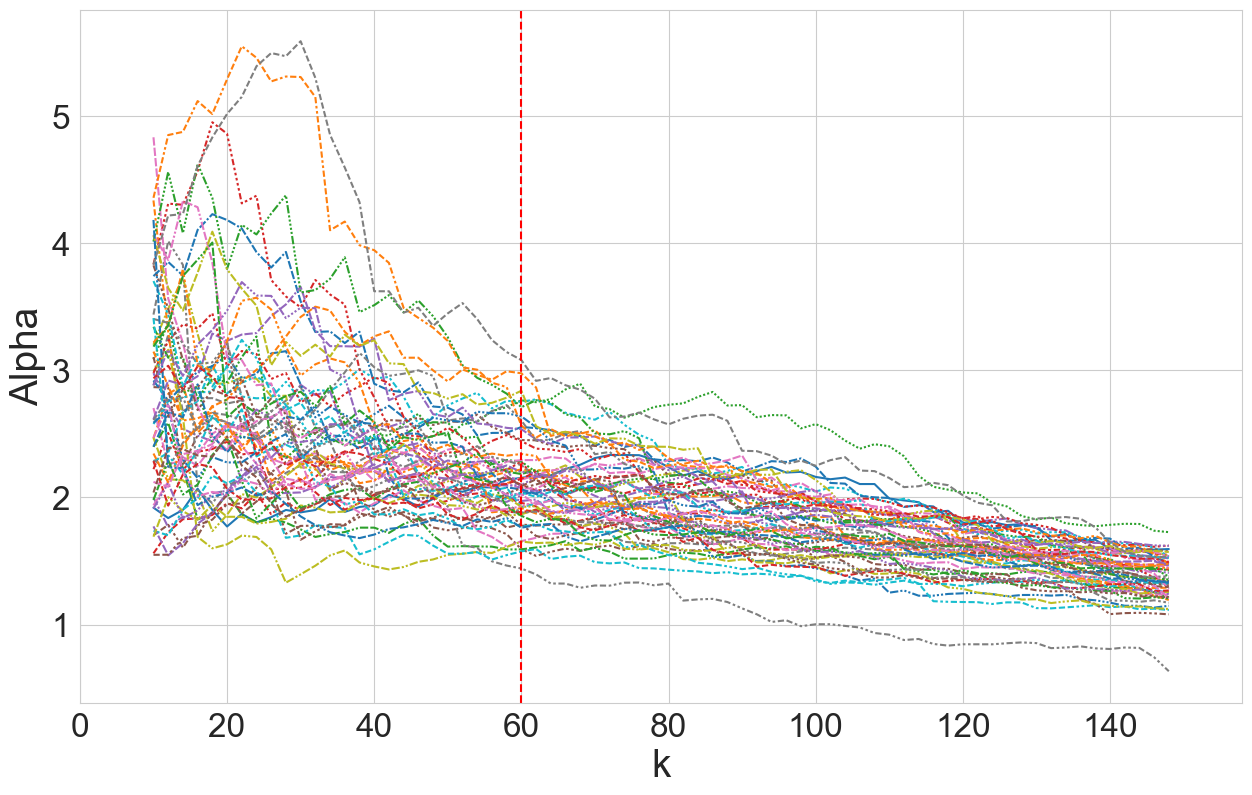

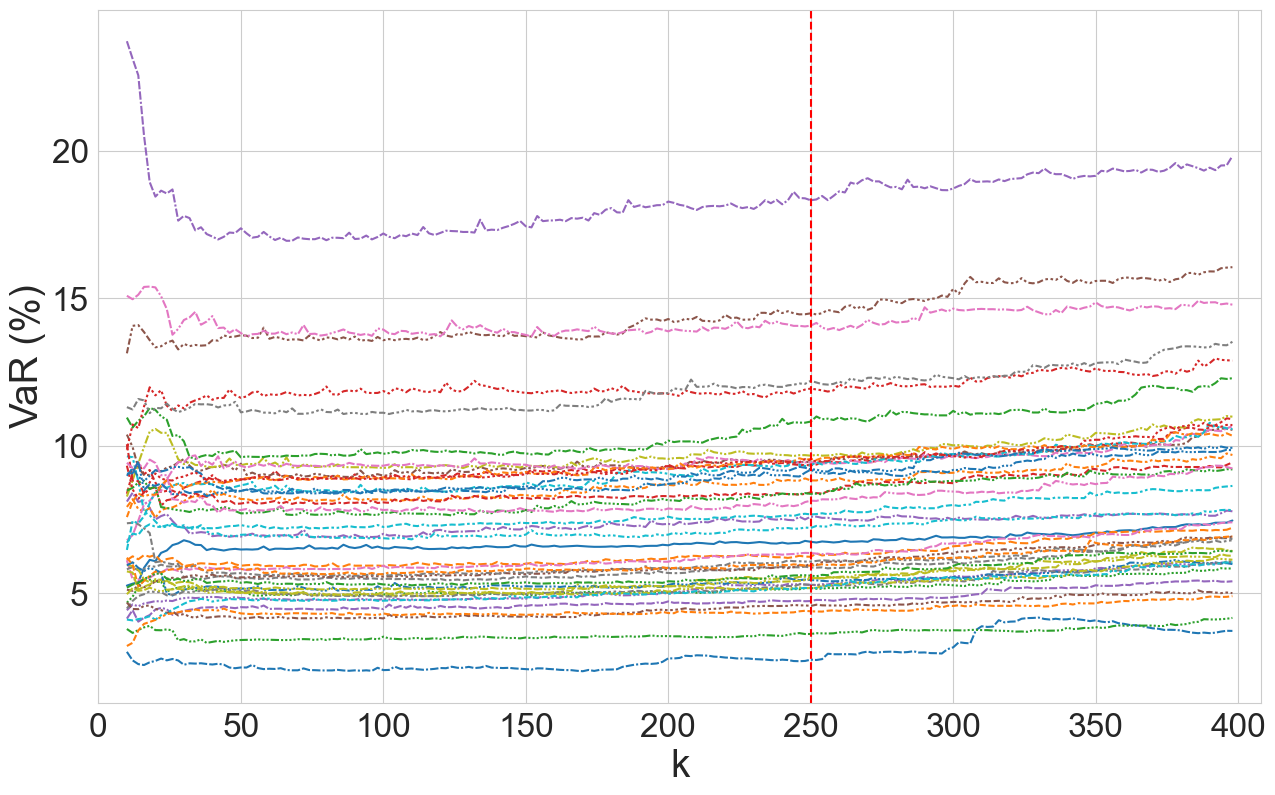

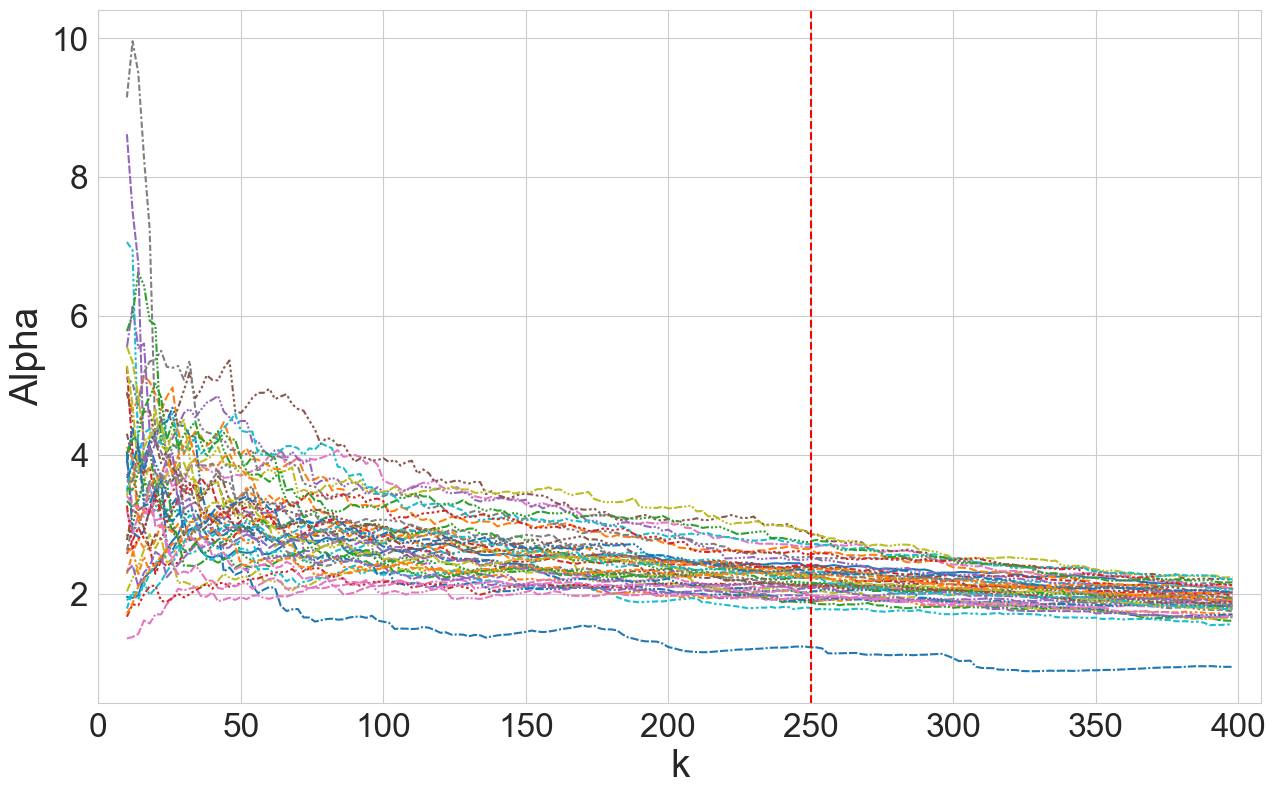

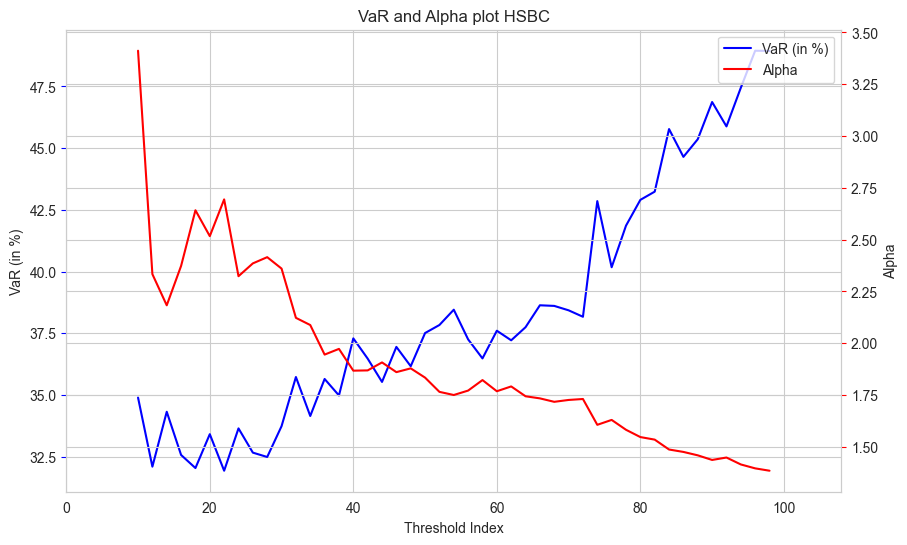

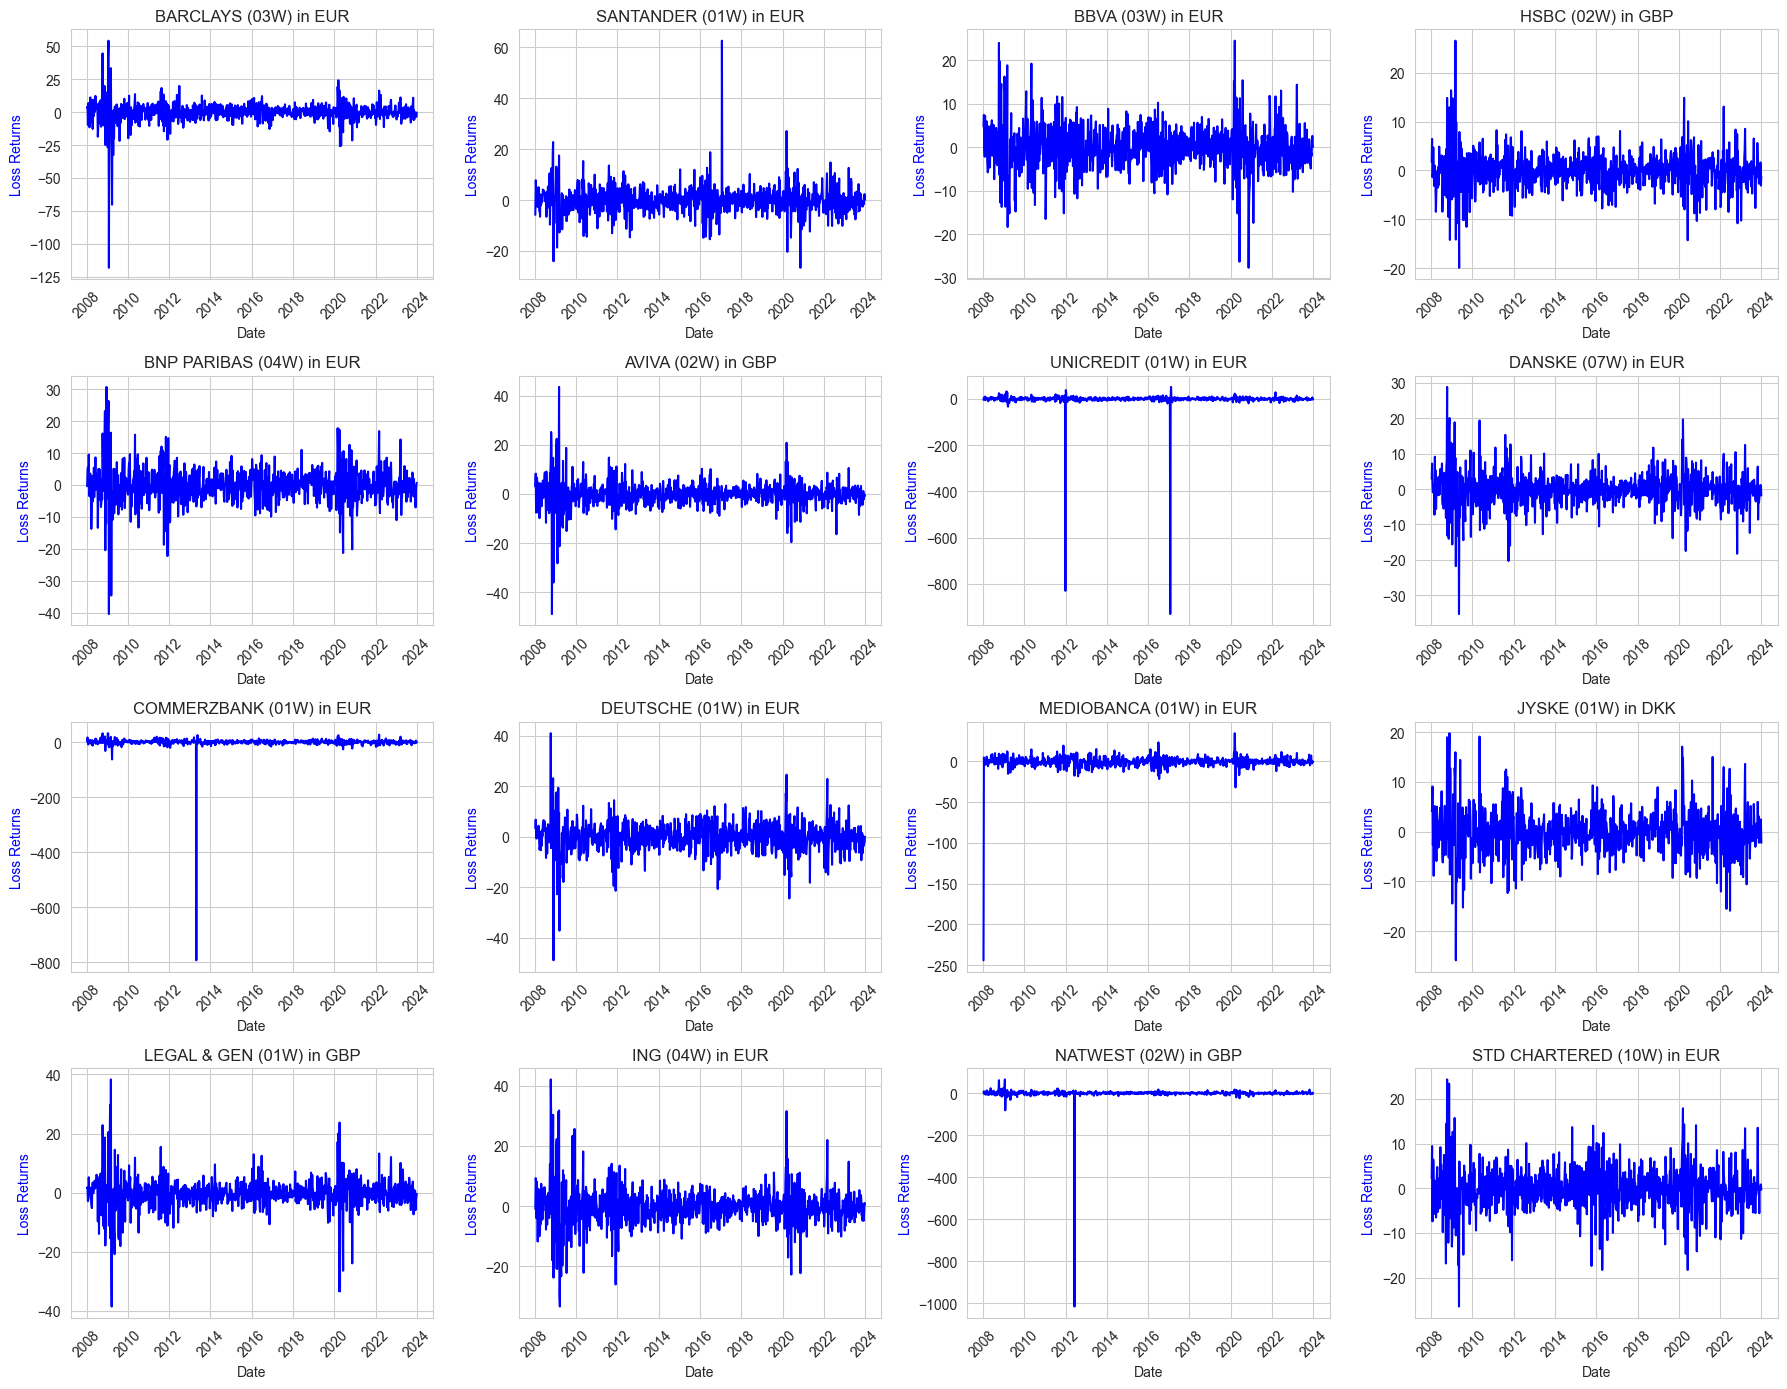

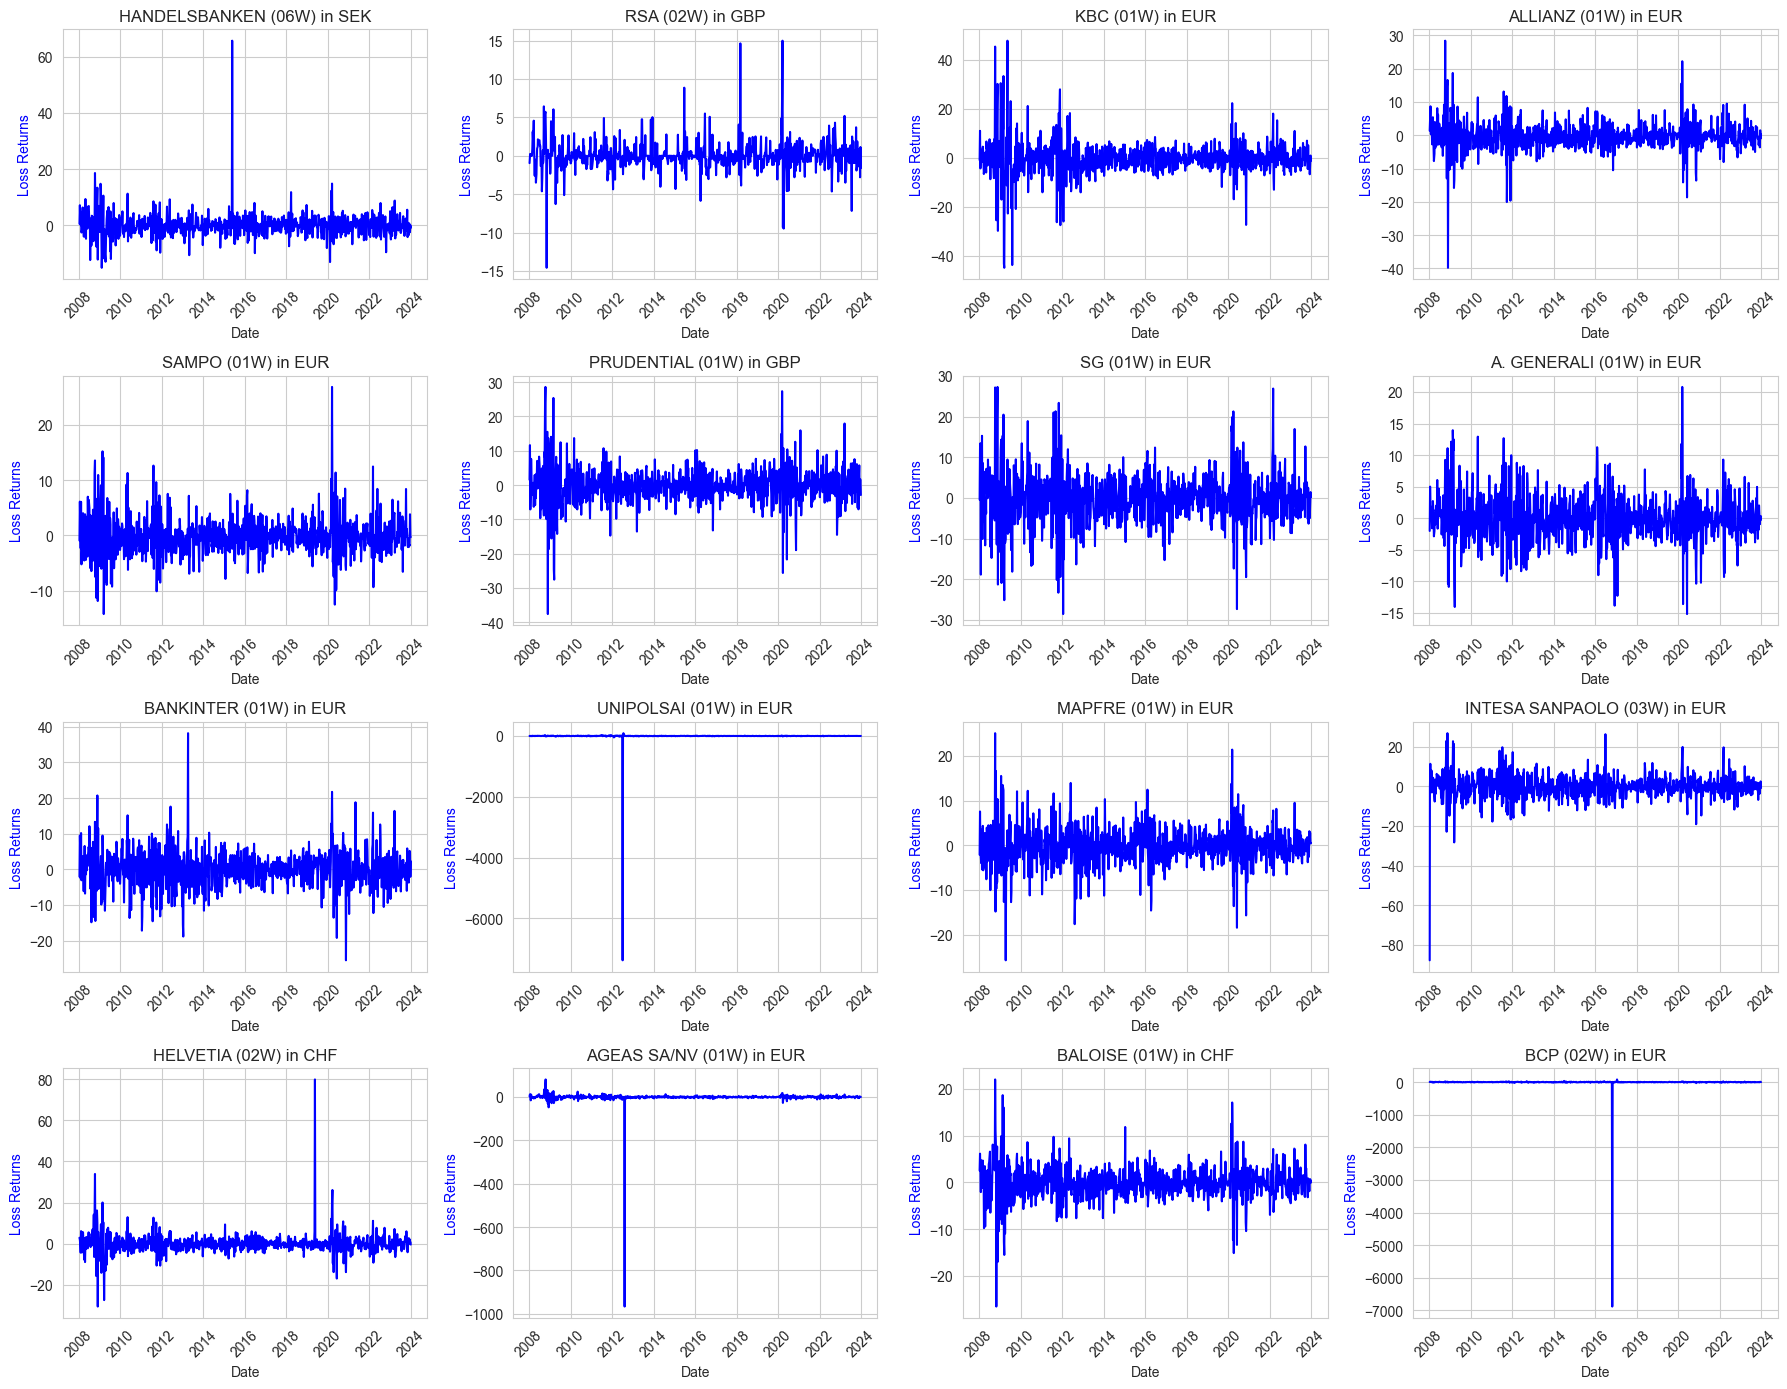

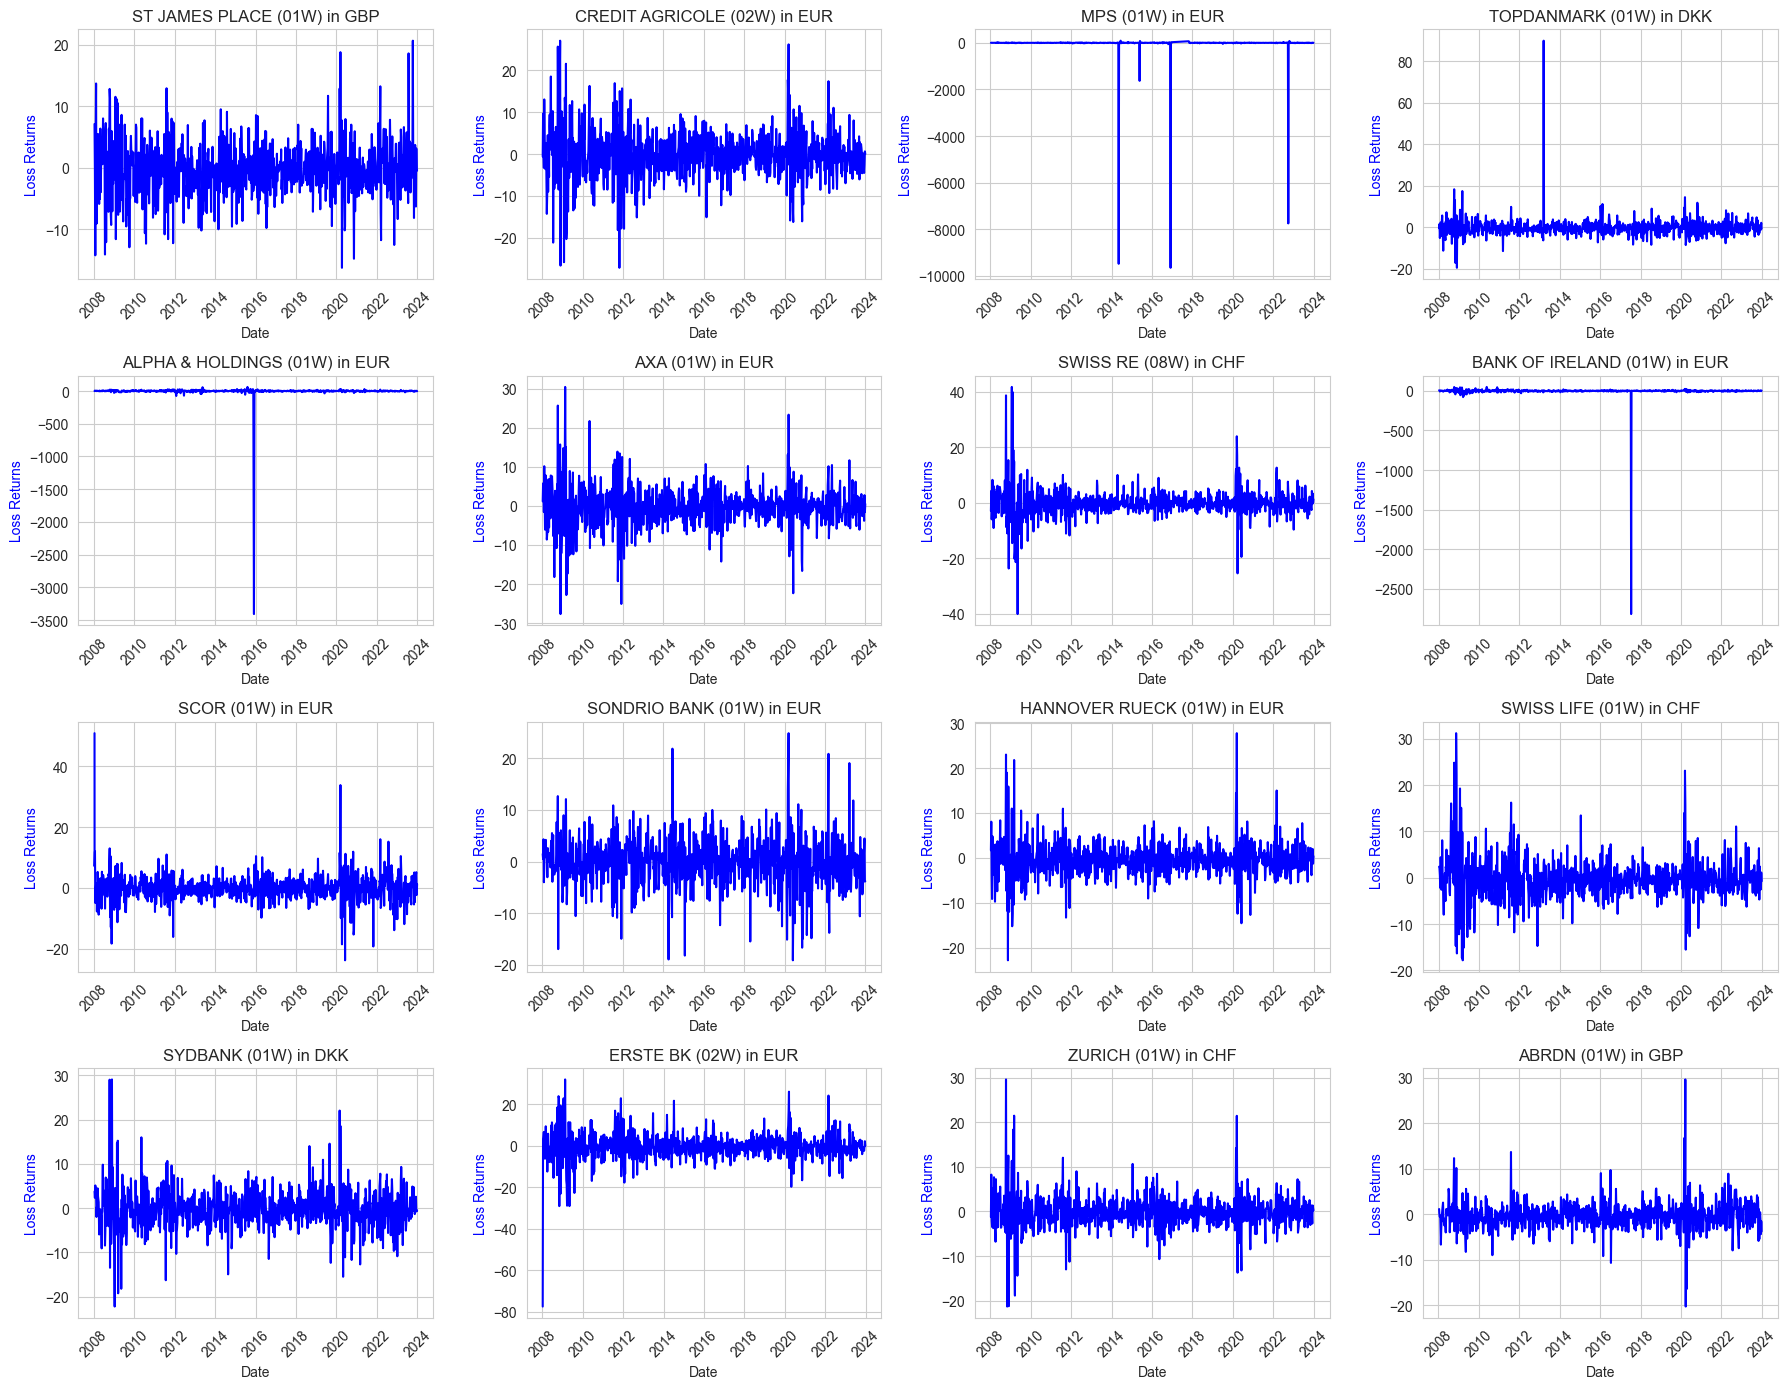

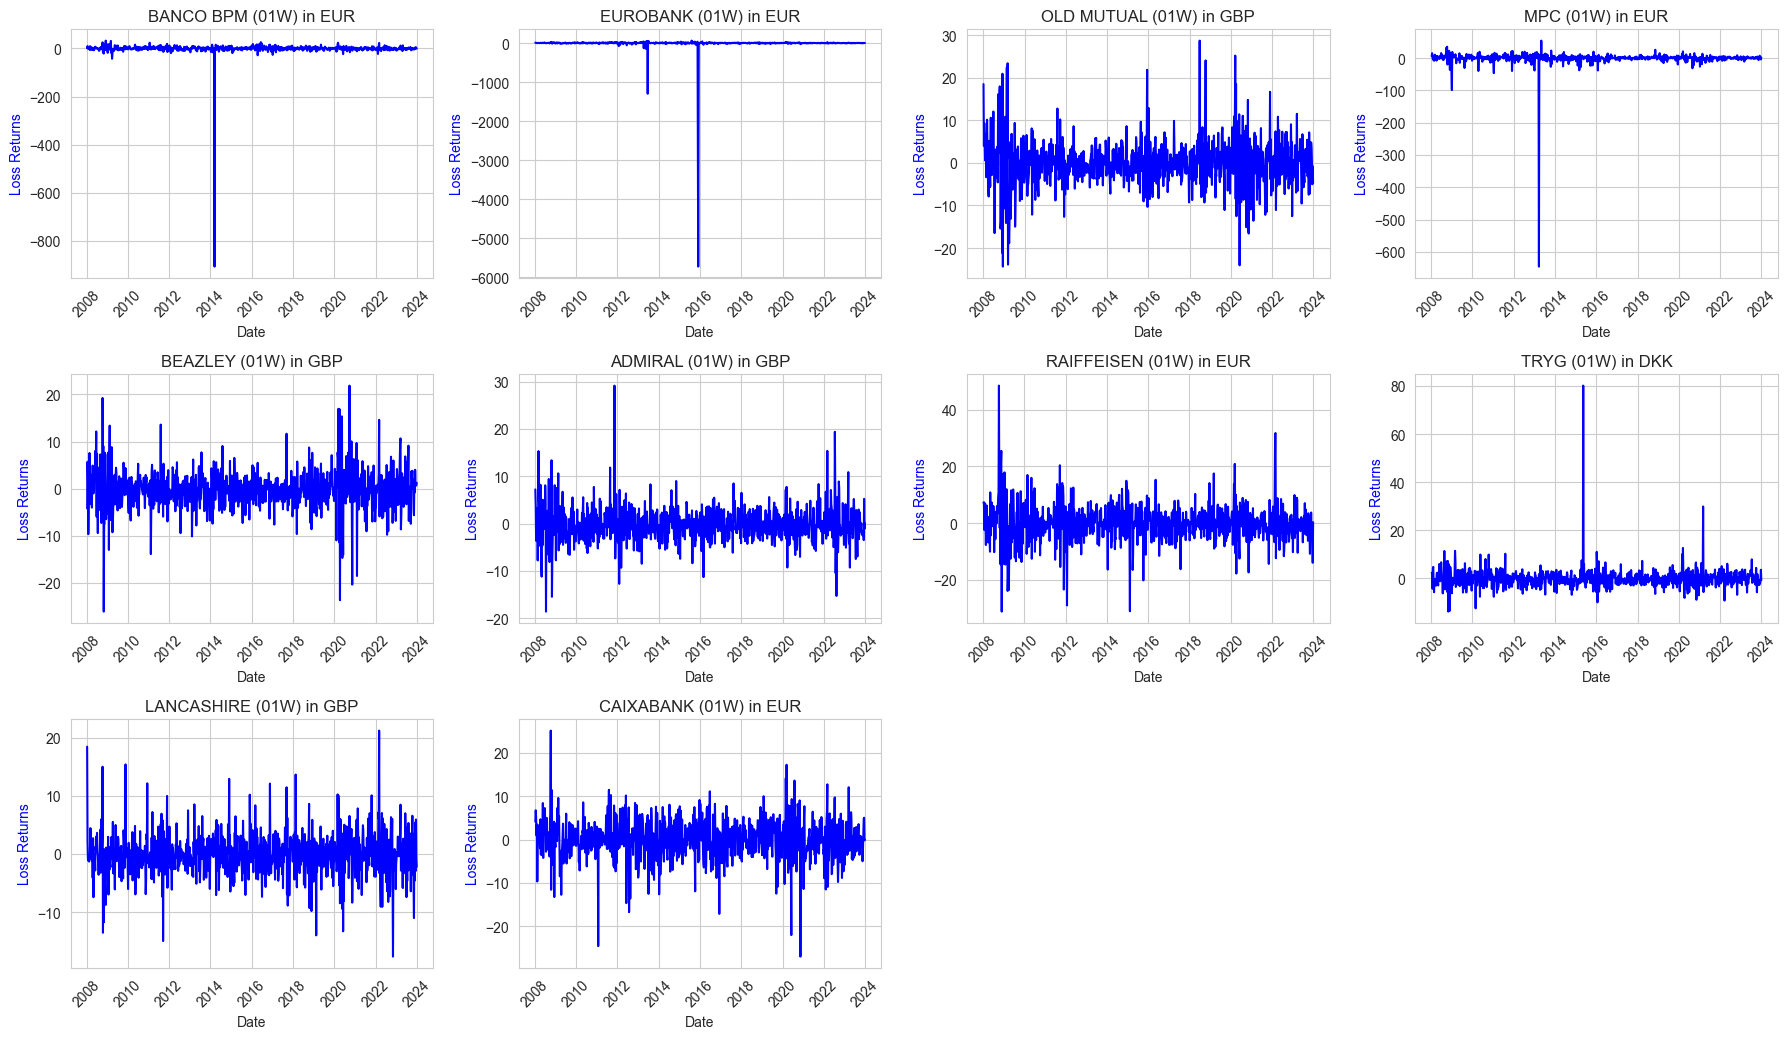

In [34]:
# ====== Alpha & VaR Plots ======
k_thresh = 60
k_thresh_day = 250

alpha_var_agg_plot(
    losses=losses_week_est, k_values=np.arange(10, 150, 2), vline=k_thresh,
    threshold=0.99,dict_gvkey_conm=dict_gvkey_conm, details_on=False,
)
alpha_var_agg_plot(
    losses=losses_day_est, k_values=np.arange(10, 400, 2), vline=k_thresh_day,
    threshold=0.99, dict_gvkey_conm=dict_gvkey_conm, details_on=False,
)
alpha_var_sing_plot(
    losses=losses_week_est[(63590, "EUR", "01W")], k_values=np.arange(10, 100, 2), name=dict_gvkey_conm[15509],
)
loss_return_plot(
    losses=losses_week, dict_gvkey_conm=dict_gvkey_conm, plots_per_batch=16, num_columns=4
)

## <-- <i>Click here to collapse Common Tail Index Testing</i>

<hr>
<br>
<center>
<h2><b><span style="color:magenta">Common Tail Index Testing</span></b></h2>
</center>
<hr>

#### `Chen & Zhou and Wald test`

In [35]:
# ====== Common tail index testing ======
alpha_dict = get_alpha_dict(losses_week_est, k_threshold=k_thresh)
alpha_list = list(alpha_dict.values())
mean_alpha = np.mean(alpha_list)

alpha_dict_day = get_alpha_dict(losses_day_est, k_threshold=k_thresh_day)
alpha_list_day = list(alpha_dict_day.values())
mean_alpha_day = np.mean(alpha_list_day)

chenzou_stat, chenzou_p_value = chenzhou(
    alpha_list=alpha_list, common_alpha=mean_alpha, k_threshold=k_thresh
)
wald_stat, wald_p_value = wald_test(
    losses=losses_week_est, alpha_list=alpha_list, common_alpha=mean_alpha, k_threshold=k_thresh
)

chenzou_stat_day, chenzou_p_value_day = chenzhou(
    alpha_list=alpha_list_day, common_alpha=mean_alpha_day, k_threshold=k_thresh_day
)
wald_stat_day, wald_p_value_day = wald_test(
    losses=losses_day_est,
    alpha_list=alpha_list_day,
    common_alpha=mean_alpha_day,
    k_threshold=k_thresh_day,
)

#### `Histograms and Test Output`

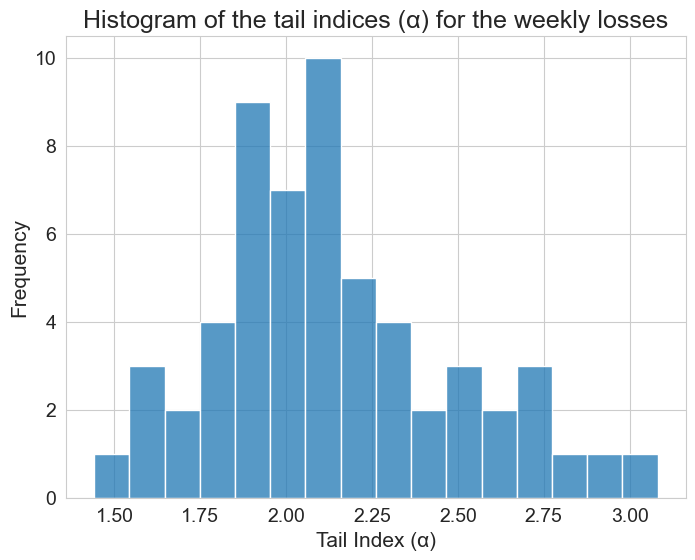

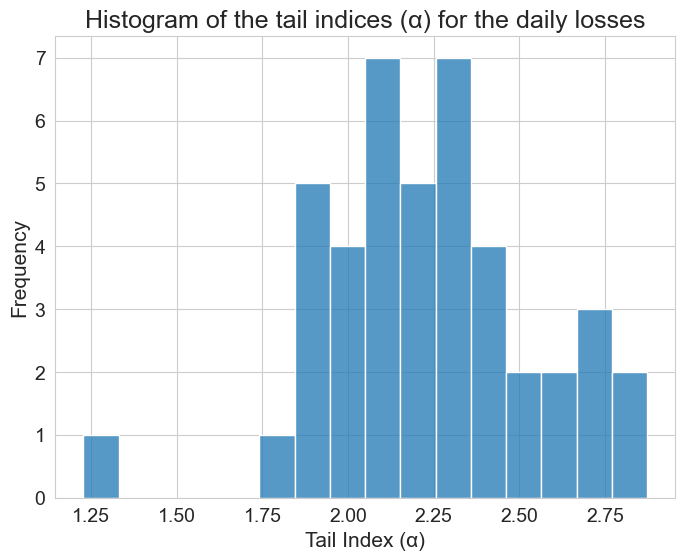

==============================Common Tail Index Testing==============================

Chenzhou statistic: 11.663520447789708, p-value: 0.046511865360156834
Wald statistic: 13769.18632642584, p-value: 0.0

Chenzhou statistic (daily): 50.91806369964417, p-value: 1.0977752040730593e-10
Wald statistic (daily): 2305.02620358728, p-value: 0.0



In [36]:
plt.figure(figsize=(8, 6))
sns.histplot(data=alpha_list, binwidth=0.10)
plt.xlabel("Tail Index (α)", fontsize=15)
plt.ylabel("Frequency", fontsize=15)
plt.title("Histogram of the tail indices (α) for the weekly losses", fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

plt.figure(figsize=(8, 6))
sns.histplot(data=alpha_list_day, binwidth=0.10)
plt.xlabel("Tail Index (α)", fontsize=15)
plt.ylabel("Frequency", fontsize=15)
plt.title("Histogram of the tail indices (α) for the daily losses", fontsize=18)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

print("=" * 30 + "Common Tail Index Testing" + "=" * 30 + "\n")
print(f"Chenzhou statistic: {chenzou_stat}, p-value: {chenzou_p_value}")
print(f"Wald statistic: {wald_stat}, p-value: {wald_p_value}\n")

print(f"Chenzhou statistic (daily): {chenzou_stat_day}, p-value: {chenzou_p_value_day}")
print(f"Wald statistic (daily): {wald_stat_day}, p-value: {wald_p_value_day}\n")
print("=" * 85)

## <-- <i>Click here to collapse KMeans Clustering</i>

<hr>
<br>
<center>
<h2><b><span style="color:orange">KMeans Clustering</span></b></h2>
</center>
<hr>

#### `KMeans`
The pooled tail indices are based upon num_cluster=4

In [37]:
print("=" * 30 + "KMeans Clustering" + "=" * 30 + "\n")
df_pooling_kmeans = kmeans_pooling(losses=losses_week_est, k_threshold=k_thresh, num_clusters=4)
kmeans_var_dict = {
    index: value
    for index, value in zip(df_pooling_kmeans.index, df_pooling_kmeans["kmeans_var"], strict=False)
}
print("KMeans Estimated parameters:\n")
print(df_pooling_kmeans.iloc[:, :])

df_pooling_kmeans_day = kmeans_pooling(
    losses=losses_day_est, k_threshold=k_thresh_day, num_clusters=4
)
kmeans_var_dict_day = {
    index: value
    for index, value in zip(
        df_pooling_kmeans_day.index, df_pooling_kmeans_day["kmeans_var"], strict=False
    )
}
print("\nKMeans Estimated parameters (daily):\n")
print(df_pooling_kmeans_day.iloc[:, :], "\n")

==============================KMeans Clustering==============================

KMeans Estimated parameters:

        kmeans_alpha  kmeans_var
12673       2.124054   19.295034
14140       2.124054   16.548830
15181       2.854297   13.306271
15509       2.124054   11.167278
15532       2.124054   16.656204
15545       1.772240   18.439381
15549       2.124054   23.010780
15552       1.772240   18.815289
15575       2.124054   22.506823
15576       2.854297   15.587669
15593       2.517219   15.136727
15600       2.124054   14.694198
15603       1.772240   15.667604
15617       2.124054   19.455556
15634       2.124054   21.018110
15645       2.517219   13.995559
15654       1.772240   13.044430
15664       1.772240    5.719037
15703       1.772240   22.731126
15724       1.772240   16.800393
15773       2.124054   11.097295
15782       1.772240   18.359705
15784       2.124054   21.523841
15804       2.124054   13.786323
15846       2.517219   14.608995
15914       1.772240   25.823085


#### `KMeans plot`

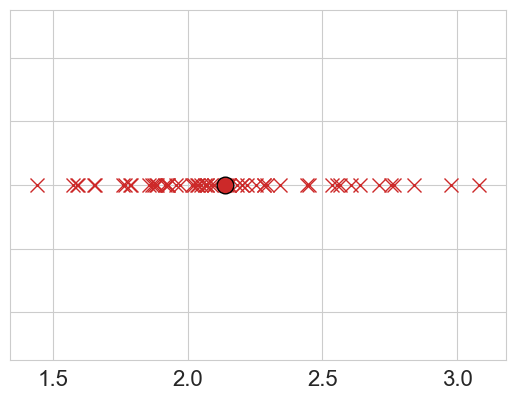

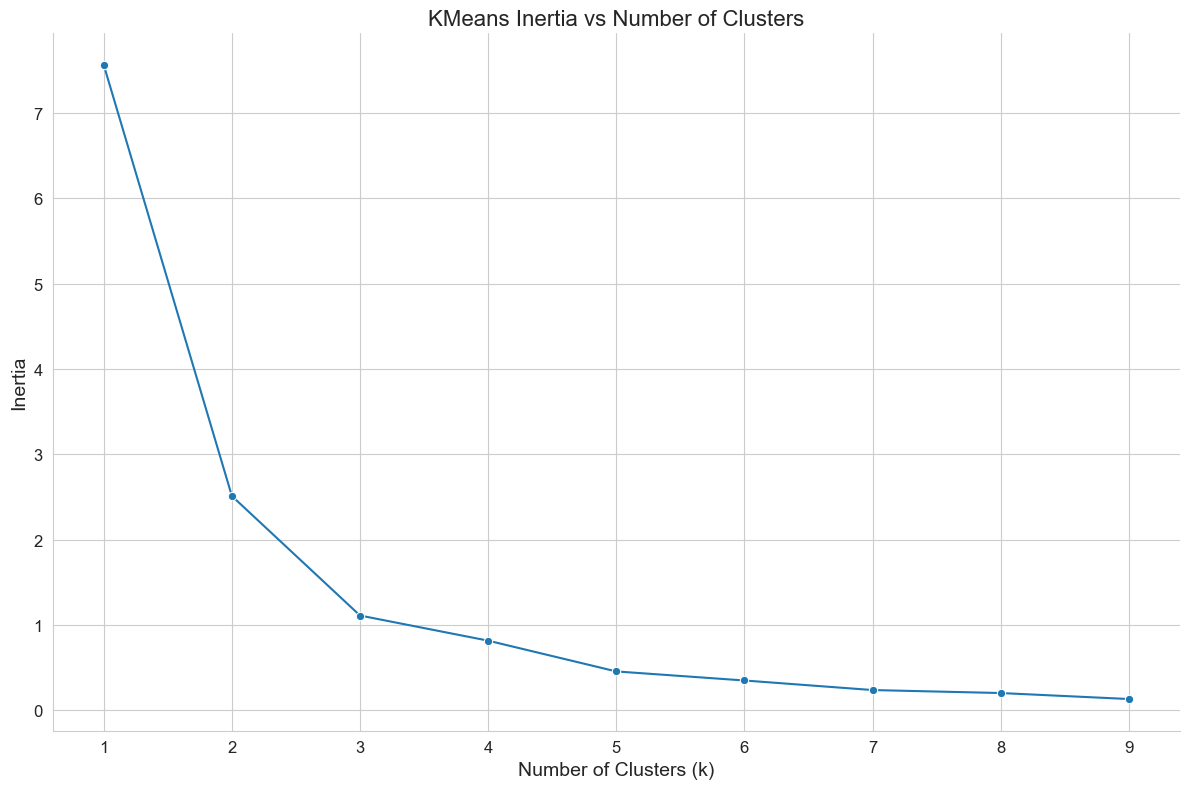

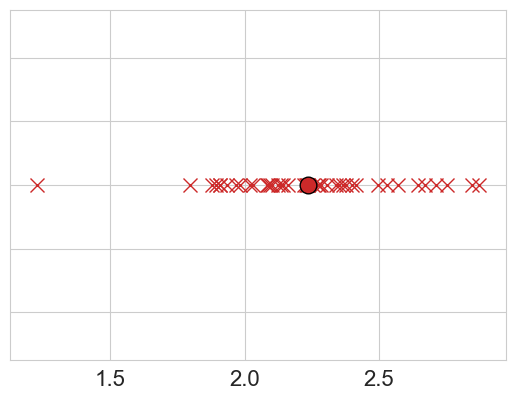

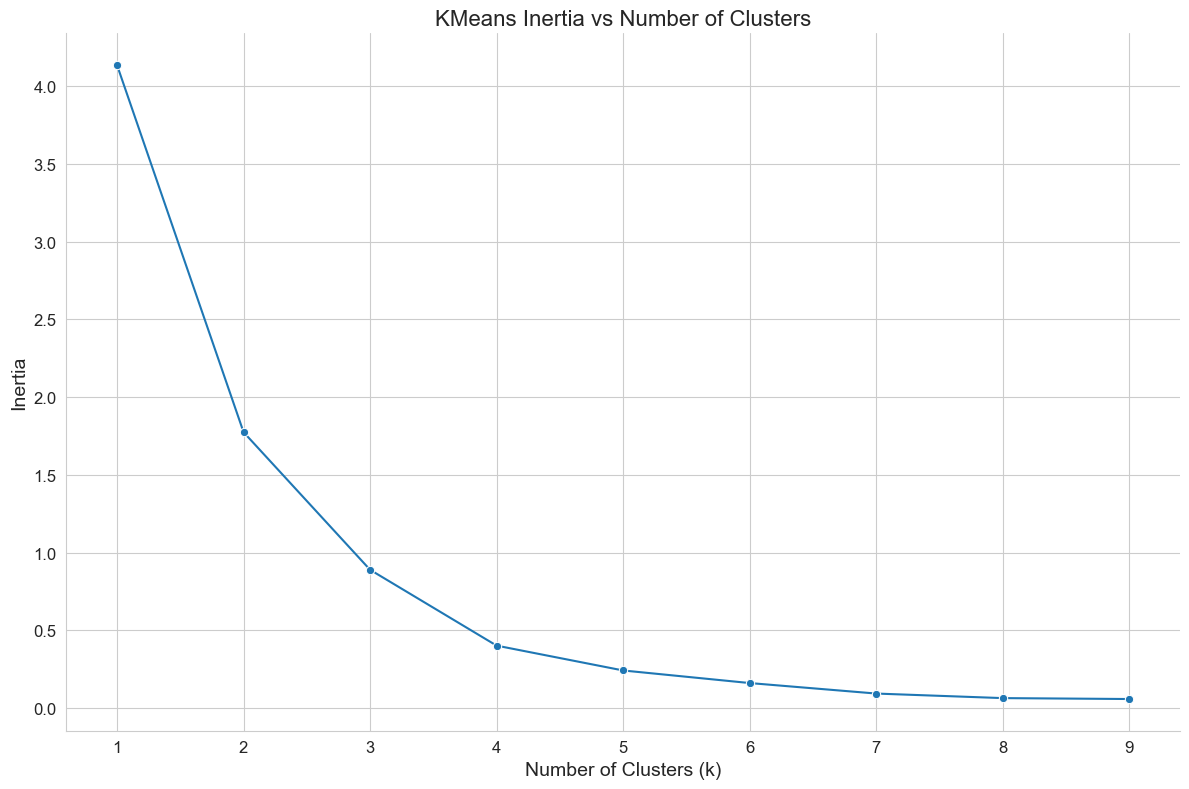

In [38]:
kmeans_plot(
    losses=losses_week_est, k_threshold=k_thresh, k_range=np.arange(1, 10), plot_inertia=True, axis_title=False,
)

kmeans_plot(
    losses=losses_day_est, k_threshold=k_thresh_day, k_range=np.arange(1, 10), plot_inertia=True, axis_title=False,
)

#### `Re-Testing Common Tail Index`

In [39]:
print("-" * 30 + "Common Tail Index Re-Testing" + "-" * 30 + "\n")

chenzhou_kmeans, wald_kmeans = [], []

for df_kmeans, k_tresh_it, losses in zip(
    (df_pooling_kmeans, df_pooling_kmeans_day),
    (60, 250),
    (losses_week_est, losses_day_est),
    strict=False,
):
    gvkey_kmeans = [
        df_kmeans.loc[df_kmeans["kmeans_alpha"] == unique_alpha].index
        for unique_alpha in [i for i in df_kmeans["kmeans_alpha"].value_counts().index]
    ]
    alpha_kmeans = [
        list(map(get_alpha_dict(losses, k_threshold=k_tresh_it).get, common_alpha_gvkey))
        for common_alpha_gvkey in gvkey_kmeans
        if common_alpha_gvkey is not None
    ]
    chenzhou_kmeans.append(
        [
            [chenzhou(alpha_list, mean_alpha, int(k_tresh_it)), mean_alpha]
            for alpha_list, mean_alpha in zip(
                alpha_kmeans, df_kmeans["kmeans_alpha"].value_counts().index, strict=False
            )
        ]
    )
    wald_kmeans.append(
        [
            [wald_test(losses[unique_alpha], alpha_list, mean_alpha, k_tresh_it), mean_alpha]
            for alpha_list, mean_alpha, unique_alpha in zip(
                alpha_kmeans,
                df_kmeans["kmeans_alpha"].value_counts().index,
                gvkey_kmeans,
                strict=False,
            )
        ]
    )

print(
    f"Chenzhou statistic (weekly) per cluster: "
    f"{
        [
            (
                round(float(test_stat[0][0]), 3),
                round(float(test_stat[0][1]), 3),
                round(test_stat[1], 3),
            )
            for test_stat in chenzhou_kmeans[0]
        ]
    }"
)
print(
    f"Wald statistic (weekly) per cluster: "
    f"{
        [
            (
                round(float(test_stat[0][0]), 3),
                round(float(test_stat[0][1]), 3),
                round(test_stat[1], 3),
            )
            for test_stat in wald_kmeans[0]
        ]
    }" + "\n"
)

print(
    f"Chenzhou statistic (daily) per cluster: "
    f"{
        [
            (
                round(float(test_stat[0][0]), 3),
                round(float(test_stat[0][1]), 3),
                round(test_stat[1], 3),
            )
            for test_stat in chenzhou_kmeans[1]
        ]
    }"
)
print(
    f"Wald statistic (daily) per cluster: "
    f"{
        [
            (
                round(float(test_stat[0][0]), 3),
                round(float(test_stat[0][1]), 3),
                round(test_stat[1], 3),
            )
            for test_stat in wald_kmeans[1]
        ]
    }" + "\n"
)

print("-" * 88 + "\n")
print("\n" + "=" * 77 + "\n")

------------------------------Common Tail Index Re-Testing------------------------------

Chenzhou statistic (weekly) per cluster: [(0.383, 0.998, 2.124), (2.097, 0.888, 1.772), (0.29, 0.933, 2.517), (0.38, 0.876, 2.854)]
Wald statistic (weekly) per cluster: [(74.787, 0.0, 2.124), (202.232, 0.0, 1.772), (8.996, 0.253, 2.517), (20.692, 0.001, 2.854)]

Chenzhou statistic (daily) per cluster: [(2.954, 0.744, 2.014), (1.509, 0.922, 2.317), (1.016, 0.848, 2.701), (0.0, 1.0, 1.227)]
Wald statistic (daily) per cluster: [(145.189, 0.0, 2.014), (61.208, 0.0, 2.317), (52.955, 0.0, 2.701), (0.0, nan, 1.227)]

----------------------------------------------------------------------------------------





## <-- <i>Click here to collapse RMTC Clustering</i>

<hr>
<br>
<center>
<h2><b><span style="color:red">RMTC Clustering</span></b></h2>
</center>
<hr>

#### `RMTC`
The starting values are:
- **Weekly losses**: ([0.4, 0.4, 0.2], [(1.9, 0.2), (2.3, 0.3), (3.0, 0.5)])
- **Daily losses**: ([0.4, 0.4, 0.2], [(1.9, 0.2), (2.3, 0.3), (2.7, 0.5)])

In [40]:
# ====== RMTC Clustering ======
df_pooling_rmtc, beta_list = rmtc_pooling(
    losses=losses_week_est,
    k_threshold=k_thresh,
    beta=([0.4, 0.4, 0.2], [(1.9, 0.2), (2.3, 0.3), (3.0, 0.5)]),
    threshold=1e-4,
    max_iter=50,
)
rmtc_var_dict = {
    index: value
    for index, value in zip(df_pooling_rmtc.index, df_pooling_rmtc["rmtc_var"], strict=False)
}
print("RMTC Estimated parameters:\n")
print(df_pooling_rmtc.iloc[:, :], "\n")
print(
    f"Estimated parameters:\n"
    f"π={[round(float(pi), 3) for pi in beta_list[-2][0]]}\n"
    f"ϕ={[(round(float(mu), 3), round(float(sigma), 3)) for mu, sigma in beta_list[-2][1]]}"
)

df_pooling_rmtc_day, beta_list_day = rmtc_pooling(
    losses=losses_day_est,
    k_threshold=k_thresh_day,
    beta=([0.4, 0.4, 0.2], [(1.9, 0.2), (2.3, 0.3), (2.7, 0.5)]),
    threshold=1e-4,
    max_iter=50,
)
rmtc_var_dict_day = {
    index: value
    for index, value in zip(
        df_pooling_rmtc_day.index, df_pooling_rmtc_day["rmtc_var"], strict=False
    )
}
print("RMTC Estimated parameters (daily):\n")
print(df_pooling_rmtc_day.iloc[:, :], "\n")
print(
    f"Estimated parameters (daily):\n"
    f"π={[round(float(pi), 3) for pi in beta_list_day[-2][0]]}\n"
    f"ϕ={[(round(float(mu), 3), round(float(sigma), 3)) for mu, sigma in beta_list_day[-2][1]]}\n"
)


==============================Robust Mixture Tail Clustering Optimization==============================

------------------------------Initializing HMIX algorithm for 3 clusters------------------------------

==============================Starting Hierarchical Mixture Optimization==============================

INITIAL PARAMETERS:
π=[0.4, 0.4, 0.2]
ϕ=[(1.9, 0.2), (2.3, 0.3), (3.0, 0.5)]

Iteration 1: h(Θ) = 0.96638858, h(Θ_t1) = 0.00000000 with: 
π=[0.4, 0.4, 0.2]
ϕ=[(1.9, 0.2), (2.3, 0.3), (3.0, 0.5)]
bounds=(1.085, 3.437)
----------------------------------------------------------------------

----------------------------------------------------------------------
Optimization result for component 0: μ_opt=1.899, σ_opt=0.207
----------------------------------------------------------------------

----------------------------------------------------------------------
Optimization result for component 1: μ_opt=2.262, σ_opt=0.296
-----------------------------------------------------------

#### `Re-Testing Common Tail Index`

In [41]:
print("-" * 30 + "Common Tail Index Re-Testing" + "-" * 30 + "\n")

chenzhou_rmtc, wald_rmtc = [], []

for df_rmtc, k_tresh_it, losses in zip(
    (df_pooling_rmtc, df_pooling_rmtc_day),
    (60, 250),
    (losses_week_est, losses_day_est),
    strict=False,
):
    gvkey_rmtc = [
        df_rmtc.loc[df_rmtc["rmtc_alpha"] == unique_alpha].index
        for unique_alpha in [i for i in df_rmtc["rmtc_alpha"].value_counts().index]
    ]
    alpha_rmtc = [
        list(map(get_alpha_dict(losses, k_threshold=k_tresh_it).get, common_alpha_gvkey))
        for common_alpha_gvkey in gvkey_rmtc
        if common_alpha_gvkey is not None
    ]
    chenzhou_rmtc.append(
        [
            [chenzhou(alpha_list, mean_alpha, int(k_tresh_it)), mean_alpha]
            for alpha_list, mean_alpha in zip(
                alpha_rmtc, df_rmtc["rmtc_alpha"].value_counts().index, strict=False
            )
        ]
    )
    wald_rmtc.append(
        [
            [wald_test(losses[unique_alpha], alpha_list, mean_alpha, k_tresh_it), mean_alpha]
            for alpha_list, mean_alpha, unique_alpha in zip(
                alpha_rmtc, df_rmtc["rmtc_alpha"].value_counts().index, gvkey_rmtc, strict=False
            )
        ]
    )

print(
    f"Chenzhou statistic (weekly) per cluster: "
    f"{
        [
            (
                round(float(test_stat[0][0]), 3),
                round(float(test_stat[0][1]), 3),
                round(test_stat[1], 3),
            )
            for test_stat in chenzhou_rmtc[0]
        ]
    }"
)
print(
    f"Wald statistic (weekly) per cluster: "
    f"{
        [
            (
                round(float(test_stat[0][0]), 3),
                round(float(test_stat[0][1]), 3),
                round(test_stat[1], 3),
            )
            for test_stat in wald_rmtc[0]
        ]
    }\n"
)

print(
    f"Chenzhou statistic (daily) per cluster: "
    f"{
        [
            (
                round(float(test_stat[0][0]), 3),
                round(float(test_stat[0][1]), 3),
                round(test_stat[1], 3),
            )
            for test_stat in chenzhou_rmtc[1]
        ]
    }"
)
print(
    f"Wald statistic (daily) per cluster: "
    f"{
        [
            (
                round(float(test_stat[0][0]), 3),
                round(float(test_stat[0][1]), 3),
                round(test_stat[1], 3),
            )
            for test_stat in wald_rmtc[1]
        ]
    }\n"
)

print("-" * 88 + "\n")
print("\n" + "=" * 77 + "\n")

------------------------------Common Tail Index Re-Testing------------------------------

Chenzhou statistic (weekly) per cluster: [(4.041, 0.782, 1.946), (2.03, 0.789, 2.201), (0.869, 0.84, 2.75)]
Wald statistic (weekly) per cluster: [(988.327, 0.0, 1.946), (167.707, 0.0, 2.201), (32.942, 0.0, 2.75)]

Chenzhou statistic (daily) per cluster: [(4.785, 0.475, 2.083), (54.273, 0.0, 2.297)]
Wald statistic (daily) per cluster: [(264.048, 0.0, 2.083), (1231.772, 0.0, 2.297)]

----------------------------------------------------------------------------------------





## <-- <i>Click here to collapse Backtesting and DM</i>

<hr>
<br>
<center>
<h2><b><span style="color:cyan">Backtesting and DM</span></b></h2>
</center>
<hr>

#### `Basel Backtesting`

In [42]:
# ====== Backtesting ======
losses_week_eval.columns = [col[0] for col in losses_week_eval.columns]
losses_day_eval.columns = [col[0] for col in losses_day_eval.columns]

print("=" * 30 + "Basel Backtesting" + "=" * 30 + "\n")
df_backtesting_non_pooling = basel_backtesting(
    losses=losses_week_eval,
    var_dict=get_var_dict(losses_week_est, k_threshold=k_thresh),
    confidence=0.99,
)
df_backtesting_non_pooling.rename(index=dict_gvkey_conm, inplace=True)
print("Backtesting results non-pooling:")
print(df_backtesting_non_pooling.iloc[:, :], "\n")

df_backtesting_non_pooling_day = basel_backtesting(
    losses=losses_day_eval,
    var_dict=get_var_dict(losses_day_est, k_threshold=k_thresh_day),
    confidence=0.99,
)
df_backtesting_non_pooling_day.rename(index=dict_gvkey_conm, inplace=True)
print("Backtesting results non-pooling (daily):")
print(df_backtesting_non_pooling_day.iloc[:, :], "\n")


df_backtesting_kmeans = basel_backtesting(
    losses=losses_week_eval, var_dict=kmeans_var_dict, confidence=0.99
)
df_backtesting_kmeans.rename(index=dict_gvkey_conm, inplace=True)
print("Backtesting results KMeans:")
print(df_backtesting_kmeans.iloc[:, :], "\n")

df_backtesting_kmeans_day = basel_backtesting(
    losses=losses_day_eval, var_dict=kmeans_var_dict_day, confidence=0.99
)
df_backtesting_kmeans_day.rename(index=dict_gvkey_conm, inplace=True)
print("Backtesting results KMeans (daily):")
print(df_backtesting_kmeans_day.iloc[:, :], "\n")


df_backtesting_rmtc = basel_backtesting(
    losses=losses_week_eval, var_dict=rmtc_var_dict, confidence=0.99
)
df_backtesting_rmtc.rename(index=dict_gvkey_conm, inplace=True)
print("Backtesting results RMTC:")
print(df_backtesting_rmtc.iloc[:, :], "\n")

df_backtesting_rmtc_day = basel_backtesting(
    losses=losses_day_eval, var_dict=rmtc_var_dict_day, confidence=0.99
)
df_backtesting_rmtc_day.rename(index=dict_gvkey_conm, inplace=True)
print("Backtesting results RMTC (daily):")
print(df_backtesting_rmtc_day.iloc[:, :], "\n")
print("=" * 77 + "\n")

==============================Basel Backtesting==============================

Backtesting results non-pooling:
                        VaR  violation_count    zone
BARCLAYS          19.001278                2   green
BALOISE            9.815495                3   green
BCP               20.754094                1   green
ST JAMES PLACE    11.731765                5   green
CREDIT AGRICOLE   17.512119                2   green
MPS               31.496663                2   green
TOPDANMARK        11.245667                2   green
ALPHA & HOLDINGS  33.233020                0   green
AXA               16.557090                1   green
SWISS RE          14.684342                2   green
BANK OF IRELAND   37.604743                0   green
SCOR              11.526320                5   green
SONDRIO BANK      12.864551                5   green
HANNOVER RUECK    10.920063                3   green
SWISS LIFE        15.915989                1   green
SYDBANK           13.870495             

#### `Sener Backtesting`

In [43]:
# ====== Sener backtesting ======
print("=" * 30 + "Sener Backtesting" + "=" * 30 + "\n")
df_sener_backtesting_non_pooling = sener_backtesting(
    losses=losses_week_eval, var_dict=get_var_dict(losses_week_est, k_threshold=k_thresh), theta=0.5
)
df_sener_backtesting_non_pooling.rename(index=dict_gvkey_conm, inplace=True)
print("Sener backtesting results non-pooling:")
print(df_sener_backtesting_non_pooling.iloc[:, :], "\n")

df_sener_backtesting_non_pooling_day = sener_backtesting(
    losses=losses_day_eval,
    var_dict=get_var_dict(losses_day_est, k_threshold=k_thresh_day),
    theta=0.5,
)
df_sener_backtesting_non_pooling_day.rename(index=dict_gvkey_conm, inplace=True)
print("Sener backtesting results non-pooling (daily):")
print(df_sener_backtesting_non_pooling_day.iloc[:, :], "\n")

df_sener_backtesting_kmeans = sener_backtesting(
    losses=losses_week_eval, var_dict=kmeans_var_dict, theta=0.5
)
df_sener_backtesting_kmeans.rename(index=dict_gvkey_conm, inplace=True)
print("Sener backtesting results KMeans:")
print(df_sener_backtesting_kmeans.iloc[:, :], "\n")

df_sener_backtesting_kmeans_day = sener_backtesting(
    losses=losses_day_eval, var_dict=kmeans_var_dict_day, theta=0.5
)
df_sener_backtesting_kmeans_day.rename(index=dict_gvkey_conm, inplace=True)
print("Sener backtesting results KMeans (daily):")
print(df_sener_backtesting_kmeans_day.iloc[:, :], "\n")

df_sener_backtesting_rmtc = sener_backtesting(
    losses=losses_week_eval, var_dict=rmtc_var_dict, theta=0.5
)
df_sener_backtesting_rmtc.rename(index=dict_gvkey_conm, inplace=True)
print("Sener backtesting results RMTC:")
print(df_sener_backtesting_rmtc.iloc[:, :], "\n")

df_sener_backtesting_rmtc_day = sener_backtesting(
    losses=losses_day_eval, var_dict=rmtc_var_dict_day, theta=0.5
)
df_sener_backtesting_rmtc_day.rename(index=dict_gvkey_conm, inplace=True)
print("Sener backtesting results RMTC (daily):")
print(df_sener_backtesting_rmtc_day.iloc[:, :], "\n")
print("=" * 77 + "\n")

==============================Sener Backtesting==============================

Sener backtesting results non-pooling:
                        VaR  violation_penalty  safe_penalty  agg_penalty
BARCLAYS          19.001278           0.772038   1798.588225   899.680132
SANTANDER         16.300162           0.000000   1574.325466   787.162733
BBVA              13.667792           4.082520   1237.697534   620.890027
HSBC              11.320163           0.028739   1103.611982   551.820360
BNP PARIBAS       18.142853           0.000000   1612.261967   806.130983
AVIVA             21.424501           0.000000   2263.272920  1131.636460
UNICREDIT         23.639005           0.000000   2113.313473  1056.656737
DANSKE            17.503205           0.000000   1926.798701   963.399350
COMMERZBANK       21.647696           0.057420   1997.161794   998.609607
DEUTSCHE          16.067575           2.739091   1394.265426   698.502258
MEDIOBANCA        14.932614           0.000000   1307.128469   653.5

#### `Diebold & Mariano`

In [44]:
# ====== Diebold-Mariano test ======
print("=" * 30 + "Diebold-Mariano Test" + "=" * 30 + "\n")
kmeans_dm_test = dm_test(
    losses=losses_week_eval,
    var_dict1=get_var_dict(losses_week_est, k_threshold=k_thresh),
    var_dict2=kmeans_var_dict,
)
kmeans_dm_test.rename(index=dict_gvkey_conm, inplace=True)
print("Diebold-Mariano test results (non-pooling vs KMeans):")
print(kmeans_dm_test.iloc[:, :], "\n")

kmeans_dm_test_day = dm_test(
    losses=losses_day_eval,
    var_dict1=get_var_dict(losses_day_est, k_threshold=k_thresh_day),
    var_dict2=kmeans_var_dict_day,
)
kmeans_dm_test_day.rename(index=dict_gvkey_conm, inplace=True)
print("Diebold-Mariano test results (non-pooling vs KMeans, daily):")
print(kmeans_dm_test_day.iloc[:, :], "\n")

rmtc_dm_test = dm_test(
    losses=losses_week_eval,
    var_dict1=get_var_dict(losses_week_est, k_threshold=k_thresh),
    var_dict2=rmtc_var_dict,
)
rmtc_dm_test.rename(index=dict_gvkey_conm, inplace=True)
print("Diebold-Mariano test results (non-pooling vs RMTC):")
print(rmtc_dm_test.iloc[:, :], "\n")

rmtc_dm_test_day = dm_test(
    losses=losses_day_eval,
    var_dict1=get_var_dict(losses_day_est, k_threshold=k_thresh_day),
    var_dict2=rmtc_var_dict_day,
)
rmtc_dm_test_day.rename(index=dict_gvkey_conm, inplace=True)
print("Diebold-Mariano test results (non-pooling vs RMTC, daily):")
print(rmtc_dm_test_day.iloc[:, :], "\n")

kmeans_rmtc_dm_test = dm_test(
    losses=losses_week_eval,
    var_dict1=kmeans_var_dict,
    var_dict2=rmtc_var_dict,
)
kmeans_rmtc_dm_test.rename(index=dict_gvkey_conm, inplace=True)
print("Diebold-Mariano test results (KMeans vs RMTC):")
print(kmeans_rmtc_dm_test.iloc[:, :], "\n")

kmeans_rmtc_dm_test_day = dm_test(
    losses=losses_day_eval,
    var_dict1=kmeans_var_dict_day,
    var_dict2=rmtc_var_dict_day,
)
kmeans_rmtc_dm_test_day.rename(index=dict_gvkey_conm, inplace=True)
print("Diebold-Mariano test results (KMeans vs RMTC, daily):")
print(kmeans_rmtc_dm_test_day.iloc[:, :], "\n")
print("=" * 80 + "\n")

==============================Diebold-Mariano Test==============================

Diebold-Mariano test results (non-pooling vs KMeans):
                   VaR1   VaR2               DM_stat  p_value  \
UNIPOLSAI        25.509 25.823                   inf    0.000   
AGEAS SA/NV      23.140 19.600  8217502272472532.000    0.000   
MPC              26.814 25.001  4732063380491561.000    0.000   
KBC              25.016 22.731  3954631448513803.000    0.000   
EUROBANK         43.414 41.415  2240952920694678.750    0.000   
NATWEST          22.292 21.018  1103497083464861.250    0.000   
BANK OF IRELAND  37.605 37.475    90159841383585.906    0.000   
BNP PARIBAS      18.143 16.656                 5.104    0.000   
AVIVA            21.425 18.439                 4.034    0.000   
HANDELSBANKEN    14.324 13.044                 3.218    0.001   
BANCO BPM        22.190 22.095                 2.045    0.020   
STD CHARTERED    14.349 13.996                 1.186    0.118   
HSBC             11

## <-- <i>Click here to collapse LaTex</i>

<hr>
<br>
<center>
<h2><b><span style="color:darkgreen">LaTex</span></b></h2>
</center>
<hr>

#### `Pooling results all methods`

In [45]:
# ====== Save results to LaTeX files ======
df_pooling_latex = (
    pd.merge(
        pd.merge(
            pd.merge(
                pd.DataFrame.from_dict(
                    get_alpha_dict(losses_week_est, k_threshold=k_thresh), orient="index"
                ),
                pd.DataFrame.from_dict(
                    get_var_dict(losses_week_est, k_threshold=k_thresh), orient="index"
                ),
                left_index=True,
                right_index=True,
            ),
            pd.merge(df_pooling_kmeans, df_pooling_rmtc, left_index=True, right_index=True),
            left_index=True,
            right_index=True,
        ).rename(columns={"0_x": "alpha", "0_y": "var"}),
        pd.merge(
            pd.merge(
                pd.DataFrame.from_dict(
                    get_alpha_dict(losses_day_est, k_threshold=k_thresh_day), orient="index"
                ),
                pd.DataFrame.from_dict(
                    get_var_dict(losses_day_est, k_threshold=k_thresh_day), orient="index"
                ),
                left_index=True,
                right_index=True,
            ),
            pd.merge(df_pooling_kmeans_day, df_pooling_rmtc_day, left_index=True, right_index=True),
            left_index=True,
            right_index=True,
        ).rename(columns={"0_x": "alpha_day", "0_y": "var_day"}),
        left_index=True,
        right_index=True,
        how="left",
    )
    .rename(index=dict_gvkey_conm)
    .sort_index(ascending=True)
    .to_latex(float_format="{:.3f}".format)
)

#### `Basel backtesting results all methods`

In [46]:
df_basel_backtesting_latex = pd.merge(
    pd.merge(
        pd.merge(
            df_backtesting_non_pooling, df_backtesting_kmeans, left_index=True, right_index=True
        ),
        df_backtesting_rmtc,
        left_index=True,
        right_index=True,
    ),
    pd.merge(
        pd.merge(
            df_backtesting_non_pooling_day,
            df_backtesting_kmeans_day,
            left_index=True,
            right_index=True,
        ),
        df_backtesting_rmtc_day,
        left_index=True,
        right_index=True,
    ),
    left_index=True,
    right_index=True,
    how="left",
).iloc[:, [1, 2, 4, 5, 7, 8, 10, 11, 13, 14, 16, 17]]

df_basel_backtesting_latex["violations (zone) non-pooling"] = [
    df_basel_backtesting_latex["violation_count_x_x"][i].astype(str)
    + " ("
    + df_basel_backtesting_latex["zone_x_x"][i]
    + ")"
    for i in range(df_basel_backtesting_latex.shape[0])
]
df_basel_backtesting_latex["violations (zone) KMeans"] = [
    df_basel_backtesting_latex["violation_count_y_x"][i].astype(str)
    + " ("
    + df_basel_backtesting_latex["zone_y_x"][i]
    + ")"
    for i in range(df_basel_backtesting_latex.shape[0])
]
df_basel_backtesting_latex["violations (zone) RMTC"] = [
    df_basel_backtesting_latex["violation_count_x"][i].astype(str)
    + " ("
    + df_basel_backtesting_latex["zone_x"][i]
    + ")"
    for i in range(df_basel_backtesting_latex.shape[0])
]

df_basel_backtesting_latex["violations (zone) non-pooling (daily)"] = [
    df_basel_backtesting_latex["violation_count_x_y"][i].astype(str)
    + " ("
    + df_basel_backtesting_latex["zone_x_y"][i]
    + ")"
    if not pd.isna(df_basel_backtesting_latex["zone_x_y"][i])
    else "NaN"
    for i in range(df_basel_backtesting_latex.shape[0])
]
df_basel_backtesting_latex["violations (zone) KMeans (daily)"] = [
    df_basel_backtesting_latex["violation_count_y_y"][i].astype(str)
    + " ("
    + df_basel_backtesting_latex["zone_y_y"][i]
    + ")"
    if not pd.isna(df_basel_backtesting_latex["zone_y_y"][i])
    else "NaN"
    for i in range(df_basel_backtesting_latex.shape[0])
]
df_basel_backtesting_latex["violations (zone) RMTC (daily)"] = [
    df_basel_backtesting_latex["violation_count_y"][i].astype(str)
    + " ("
    + df_basel_backtesting_latex["zone_y"][i]
    + ")"
    if not pd.isna(df_basel_backtesting_latex["zone_y"][i])
    else "NaN"
    for i in range(df_basel_backtesting_latex.shape[0])
]
df_basel_backtesting_latex = df_basel_backtesting_latex.iloc[:, -6:].to_latex()

#### `Sener backtesting all methods`

In [47]:
df_sener_backtesting_latex = (
    pd.merge(
        pd.merge(
            pd.merge(
                df_sener_backtesting_non_pooling,
                df_sener_backtesting_kmeans,
                left_index=True,
                right_index=True,
            ),
            df_sener_backtesting_rmtc,
            left_index=True,
            right_index=True,
        ),
        pd.merge(
            pd.merge(
                df_sener_backtesting_non_pooling_day,
                df_sener_backtesting_kmeans_day,
                left_index=True,
                right_index=True,
            ),
            df_sener_backtesting_rmtc_day,
            left_index=True,
            right_index=True,
        ),
        left_index=True,
        right_index=True,
        how="left",
    )
    .iloc[:, [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23]]
    .sort_index(ascending=True)
)

for col in df_sener_backtesting_latex.columns:
    if df_sener_backtesting_latex.columns.get_loc(col) % 2 == 0:
        df_sener_backtesting_latex[col] = df_sener_backtesting_latex[col].map("{:.2f}".format)
    else:
        df_sener_backtesting_latex[col] = df_sener_backtesting_latex[col].map("{:.0f}".format)

df_sener_backtesting_latex = df_sener_backtesting_latex.to_latex(index=True, escape=False)

#### `Diebold & Mariano all methods`

In [48]:
df_dm_test_latex = pd.merge(
    pd.merge(
        pd.merge(
            kmeans_dm_test.iloc[:, 2:4],
            rmtc_dm_test.iloc[:, 2:4],
            left_index=True,
            right_index=True,
        ),
        kmeans_rmtc_dm_test.iloc[:, 2:4],
        left_index=True,
        right_index=True,
    ),
    pd.merge(
        pd.merge(
            kmeans_dm_test_day.iloc[:, 2:4],
            rmtc_dm_test_day.iloc[:, 2:4],
            left_index=True,
            right_index=True,
        ),
        kmeans_rmtc_dm_test_day.iloc[:, 2:4],
        left_index=True,
        right_index=True,
    ),
    left_index=True,
    right_index=True,
    how="left",
).sort_index(ascending=True)

df_dm_test_latex["kmeans_dm"] = [
    df_dm_test_latex["DM_stat_x_x"][i].astype(str)
    + " ("
    + df_dm_test_latex["p_value_x_x"][i].astype(str)
    + ")"
    for i in range(df_dm_test_latex.shape[0])
]

df_dm_test_latex["rmtc_dm"] = [
    df_dm_test_latex["DM_stat_y_x"][i].astype(str)
    + " ("
    + df_dm_test_latex["p_value_y_x"][i].astype(str)
    + ")"
    for i in range(df_dm_test_latex.shape[0])
]

df_dm_test_latex["kmeans_rmtc_dm"] = [
    df_dm_test_latex["DM_stat_x"][i].astype(str)
    + " ("
    + df_dm_test_latex["p_value_x"][i].astype(str)
    + ")"
    for i in range(df_dm_test_latex.shape[0])
]

df_dm_test_latex["kmeans_dm_day"] = [
    df_dm_test_latex["DM_stat_x_y"][i].astype(str)
    + " ("
    + df_dm_test_latex["p_value_x_y"][i].astype(str)
    + ")"
    for i in range(df_dm_test_latex.shape[0])
]

df_dm_test_latex["rmtc_dm_day"] = [
    df_dm_test_latex["DM_stat_y_y"][i].astype(str)
    + " ("
    + df_dm_test_latex["p_value_y_y"][i].astype(str)
    + ")"
    for i in range(df_dm_test_latex.shape[0])
]

df_dm_test_latex["kmeans_rmtc_dm_day"] = [
    df_dm_test_latex["DM_stat_y_y"][i].astype(str)
    + " ("
    + df_dm_test_latex["p_value_y_y"][i].astype(str)
    + ")"
    for i in range(df_dm_test_latex.shape[0])
]

df_dm_test_latex = df_dm_test_latex.iloc[:, -6:].to_latex(index=True, escape=False)